In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df_clean = pd.read_csv("online_retail_day1_cleaned.csv")

df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [3]:
print("Dataset Shape:", df_clean.shape)

print("\nColumn Names:")
print(df_clean.columns.tolist())

print("\nDataset Information:")
df_clean.info()

Dataset Shape: (392692, 9)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalAmount']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 392692 entries, 0 to 392691
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    392692 non-null  int64  
 1   StockCode    392692 non-null  object 
 2   Description  392692 non-null  object 
 3   Quantity     392692 non-null  int64  
 4   InvoiceDate  392692 non-null  object 
 5   UnitPrice    392692 non-null  float64
 6   CustomerID   392692 non-null  float64
 7   Country      392692 non-null  object 
 8   TotalAmount  392692 non-null  float64
dtypes: float64(3), int64(2), object(4)
memory usage: 27.0+ MB


In [4]:
# Convert InvoiceDate into datetime format
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

# Convert CustomerID into integer format
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

print("Data types converted successfully!")

print("\nUpdated Data Types:")
print(df_clean.dtypes)

Data types converted successfully!

Updated Data Types:
InvoiceNo               int64
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              int64
Country                object
TotalAmount           float64
dtype: object


In [5]:
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Last Transaction Date:", df_clean["InvoiceDate"].max())
print("Reference Date:", reference_date)

Last Transaction Date: 2011-12-09 12:50:00
Reference Date: 2011-12-10 12:50:00


In [6]:
rfm = df_clean.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
})

# Rename columns
rfm.rename(columns={
    "InvoiceDate": "Recency",
    "InvoiceNo": "Frequency",
    "TotalAmount": "Monetary"
}, inplace=True)

# Display first five customers
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [7]:
print("RFM Dataset Shape:", rfm.shape)

print("\nRFM Summary:")
print(rfm.describe())

print("\nMissing Values:")
print(rfm.isnull().sum())

RFM Dataset Shape: (4338, 3)

RFM Summary:
           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2048.688081
std     100.014169     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     306.482500
50%      51.000000     2.000000     668.570000
75%     142.000000     5.000000    1660.597500
max     374.000000   209.000000  280206.020000

Missing Values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


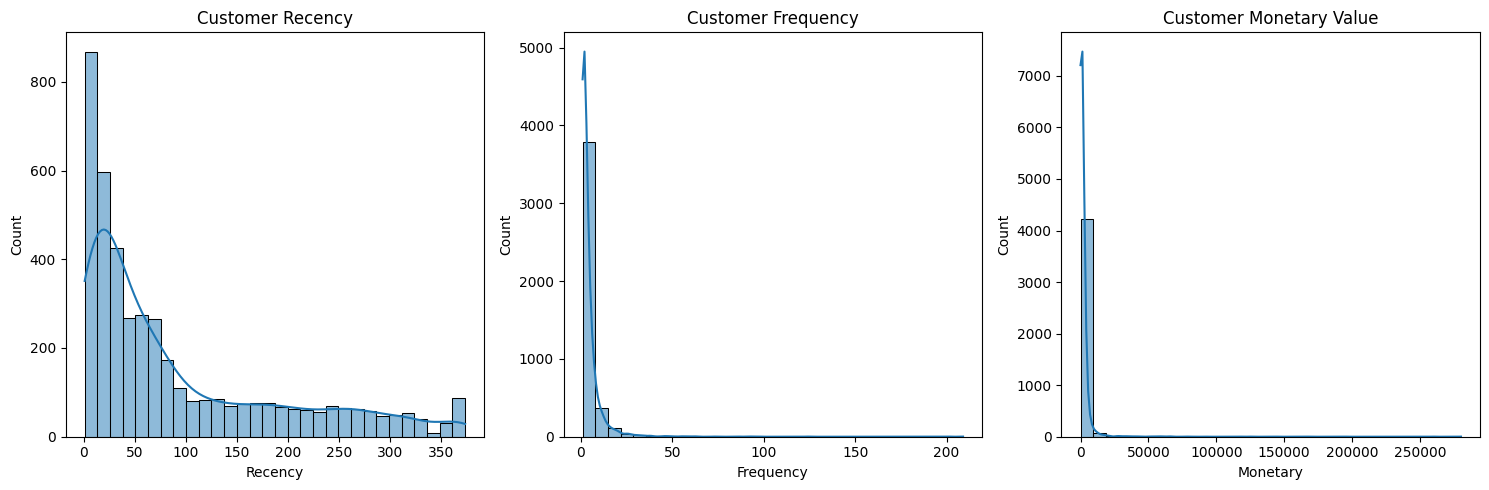

In [8]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(rfm["Recency"], bins=30, kde=True)
plt.title("Customer Recency")

plt.subplot(1, 3, 2)
sns.histplot(rfm["Frequency"], bins=30, kde=True)
plt.title("Customer Frequency")

plt.subplot(1, 3, 3)
sns.histplot(rfm["Monetary"], bins=30, kde=True)
plt.title("Customer Monetary Value")

plt.tight_layout()
plt.show()

In [9]:
top_customers = rfm.sort_values(
    by="Monetary",
    ascending=False
).head(10)

top_customers

,Recency,Frequency,Monetary
CustomerID,,,
14646,2,73,280206.02
18102,1,60,259657.30
17450,8,46,194390.79
16446,1,2,168472.50
14911,1,201,143711.17
12415,24,21,124914.53
14156,10,55,117210.08
17511,3,31,91062.38
16029,39,63,80850.84


In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

# Convert scaled data back into a DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

print("Feature scaling completed!")

rfm_scaled.head()

Feature scaling completed!


,Recency,Frequency,Monetary
CustomerID,,,
12346,1.461993,-0.955214,3.707716
12347,-2.038734,1.074425,1.414903
12348,0.373104,0.386304,0.720024
12349,-0.623086,-0.955214,0.702287
12350,1.424558,-0.955214,-0.614514


In [14]:
rfm.to_csv("customer_rfm_features.csv")

print("Customer RFM feature table saved successfully!")

Customer RFM feature table saved successfully!
